In [1]:
print("hello")

hello


In [3]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

load_dotenv()

True

In [5]:
models = init_chat_model(
    model="openai/gpt-oss-20b",
    model_provider="groq",
)

summarization middleware

In [6]:
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage

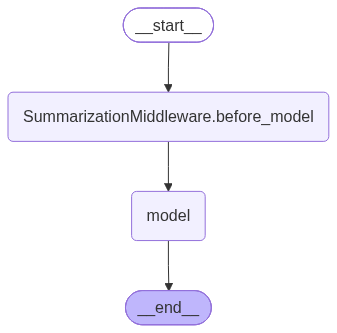

In [7]:
agent = create_agent(
    model=models,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=models,
            trigger=("messages",10),
            keep=("messages",4)
            
        )
    ]
)

agent

In [8]:
confg ={"configurable":{"thread_id":"test1"}}

In [9]:
question=[
    "what is 2+2?",
    "what is 10*5",
    "what is 100/4",
    "what is 15-7",
    "what is 3*3",
    "what is 4*2"
]

In [11]:
for q in question:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config=confg)
    print(f"{response}")

{'messages': [HumanMessage(content='Here is a summary of the conversation to date:\n\n## SESSION INTENT\nProvide correct arithmetic results for basic math queries.\n\n## SUMMARY\nThe user has asked a series of simple arithmetic questions:\n- 2\u202f+\u202f2 → 4\n- 10\u202f×\u202f5 → 50\n- 100 ÷ 4 → 25\nThe user has also asked for the result of 15\u202f–\u202f7, which has not yet been answered.\n\n## ARTIFACTS\nNone.\n\n## NEXT STEPS\nRespond with the correct answer: 15\u202f–\u202f7\u202f=\u202f8.', additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='178cbbc1-5192-4537-b32e-5cc015029735'), AIMessage(content='15\u202f−\u202f7\u202f=\u202f8', additional_kwargs={'reasoning_content': 'User asks simple arithmetic. We answer.'}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 153, 'total_tokens': 180, 'completion_time': 0.030137246, 'completion_tokens_details': {'reasoning_tokens': 9}, 'prompt_time': 0.007719432, 'prompt_tokens_details': N